<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_074_anomaly_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 74/365 — Anomaly Detection
## How do we find rare observations that do not behave like the rest?

Anomaly detection is the task of finding unusual observations.

Examples:
- suspicious transactions
- unusual logins
- failing machine sensors
- abnormal traffic spikes
- unexpected customer behavior

The challenge: anomalies are usually rare.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Create mostly normal data with a few unusual values


In [2]:
rng=np.random.default_rng(42)

normal_data=rng.normal(
    loc=50,
    scale=8,
    size=500
)

anomalies=np.array([8,12,15,90,95,102])

values=np.concatenate([normal_data,anomalies])

df=pd.DataFrame({"value":values})

print("Total observations:",len(df))


Total observations: 506


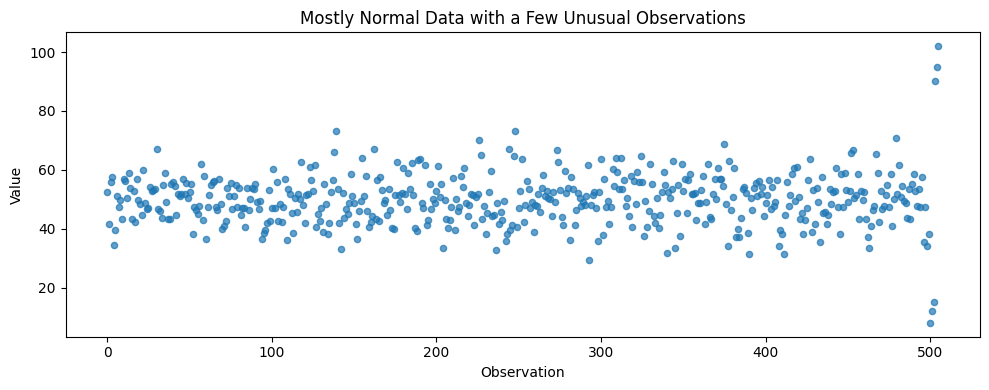

In [3]:
plt.figure(figsize=(10,4))
plt.scatter(range(len(df)),df["value"],s=20,alpha=0.7)
plt.xlabel("Observation")
plt.ylabel("Value")
plt.title("Mostly Normal Data with a Few Unusual Observations")
plt.tight_layout()
plt.show()


## 2. Simple statistical anomaly detection with Z-score

Formula:

`z = (x - mean) / standard deviation`

A common rule of thumb is:

`|z| > 3`

may indicate an unusual observation.


In [4]:
mean=df["value"].mean()
std=df["value"].std()

df["z_score"]=(df["value"]-mean)/std
df["is_anomaly"]=df["z_score"].abs()>3

display(
    df[df["is_anomaly"]]
    .sort_values("value")
    .round(2)
)


,value,z_score,is_anomaly
500,8.0,-4.70,True
501,12.0,-4.25,True
502,15.0,-3.92,True
503,90.0,4.49,True
504,95.0,5.05,True
505,102.0,5.84,True


## 3. Highlight detected anomalies


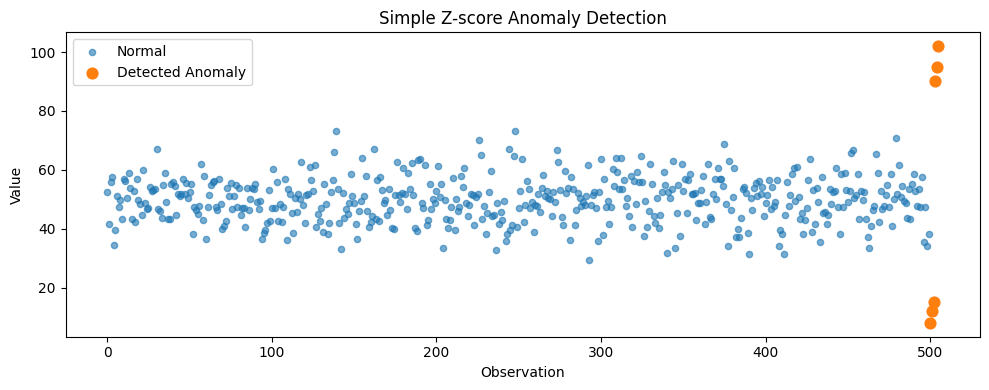

In [5]:
normal=df[~df["is_anomaly"]]
outliers=df[df["is_anomaly"]]

plt.figure(figsize=(10,4))
plt.scatter(
    normal.index,
    normal["value"],
    s=20,
    alpha=0.6,
    label="Normal"
)
plt.scatter(
    outliers.index,
    outliers["value"],
    s=60,
    label="Detected Anomaly"
)
plt.xlabel("Observation")
plt.ylabel("Value")
plt.title("Simple Z-score Anomaly Detection")
plt.legend()
plt.tight_layout()
plt.show()


## 4. Why anomaly detection is different from classification

In supervised classification, we usually have labeled classes.

In anomaly detection:
- anomalies may be extremely rare
- labels may be missing
- future anomalies may look different from historical ones

Often, the system first learns what **normal** looks like and flags deviations.


## 5. Types of anomalies

### Point anomaly
One observation is individually unusual.

### Contextual anomaly
An observation is unusual only in a specific context.

### Collective anomaly
A sequence or group becomes unusual together.


## 6. Why Z-score is not enough

Z-score is useful for intuition, but it struggles when:
- data is non-Gaussian
- multiple features interact
- the pattern is nonlinear
- there are many dimensions
- anomalies are subtle

This is where machine-learning methods become useful.


## 7. Popular anomaly-detection methods

- Z-score / statistical thresholds
- Isolation Forest
- One-Class SVM
- Local Outlier Factor
- Autoencoders

Next, we will study one of the most popular:

**Isolation Forest**


## Enterprise intuition

Anomaly detection is common in:
- fraud detection
- cybersecurity
- manufacturing
- observability
- insurance
- operational monitoring

Important:

**Anomaly does not automatically mean fraud or failure.**

It means the observation behaves differently enough to deserve attention.


## 8. Evaluation challenge

When anomaly labels exist, useful metrics include:
- Precision
- Recall
- F1 Score
- Precision-Recall Curve

Accuracy can be misleading because anomalies are rare.


## What does this teach?

- Anomaly detection finds rare/unusual observations.
- Labels are often scarce or incomplete.
- Z-score is a simple starting point.
- Real anomaly detection usually needs stronger methods.
- Context matters.
- Rare-event metrics matter more than raw accuracy.

> **Classification asks which known class something belongs to. Anomaly detection asks whether it behaves like normal data at all.**


## References

- https://scikit-learn.org/stable/modules/outlier_detection.html
- https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_anomaly_comparison.html
- https://doi.org/10.1145/1541880.1541882
